In [29]:
import pydicom
import cv2
import numpy as np
from pathlib import Path
from tqdm import tqdm

In [30]:
DICOM_ROOT = Path("/media/user2/0b7e9258-fafd-4f97-8bf0-5b86acf8e9b4/CBIS-DDSM/cbis_ddsm")
OUTPUT_ROOT = Path("/media/user2/0b7e9258-fafd-4f97-8bf0-5b86acf8e9b4/CBIS-DDSM/cbis_ddsm_jpg")
JPEG_QUALITY = 95

### Função de Normalização
Normaliza imagem 16-bit usando percentis 1 e 99.

In [31]:
def normalize_16bit(img):
    low = np.percentile(img, 1)
    high = np.percentile(img, 99)
    
    img = np.clip(img, low, high)
    img = (img - img.min()) / (img.max() - img.min() + 1e-8) * 255
    
    return img.astype(np.uint8)

### Função de Verificação de Máscaras
Verifica se a imagem é uma máscara binária checando valores únicos.

In [32]:
def is_mask(img_array):
    unique = len(np.unique(img_array))
    
    return unique <= 3

### Função de Conversão
Converte todos os DICOMs de uma pasta mantendo a estrutura original.

In [33]:
def process_folder(folder_path, output_base):

    relative = folder_path.relative_to(DICOM_ROOT)
    out_dir = output_base / relative
    out_dir.mkdir(parents=True, exist_ok=True)
    
    dcm_files = list(folder_path.rglob("*.dcm")) + list(folder_path.rglob("*.DCM"))
    
    for dcm_file in dcm_files:
        ds = pydicom.dcmread(str(dcm_file), force=True)
        
        if not hasattr(ds, 'pixel_array'):
            continue
        
        img = ds.pixel_array.astype(np.float32)
        
        if is_mask(img):
            # Salva máscara como PNG binário
            mask_binary = (img > 0).astype(np.uint8) * 255
            out_path = out_dir / f"{dcm_file.stem}_mask.png"
            cv2.imwrite(str(out_path), mask_binary)
        else:
            # Salva imagem como JPG
            if img.max() > 255:
                img = normalize_16bit(img)
            
            out_path = out_dir / f"{dcm_file.stem}.jpg"
            cv2.imwrite(str(out_path), img, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])

### Execução da Conversão

In [34]:
print("CONVERSÃO CBIS-DDSM: DICOM -> JPG/PNG\n")

pastas = sorted([f for f in DICOM_ROOT.iterdir() 
                 if f.is_dir() and ('Mass-' in f.name or 'Calc-' in f.name)])

print(f"Pastas a processar: {len(pastas)}\n")

for pasta in tqdm(pastas, desc="Convertendo", unit="pasta"):
    process_folder(pasta, OUTPUT_ROOT)

print(f"\nDataset JPG em: {OUTPUT_ROOT}")

    CONVERSÃO CBIS-DDSM: DICOM → JPG/PNG


Pastas a processar: 6268



Convertendo: 100%|█████████████████████| 6268/6268 [1:05:38<00:00,  1.59pasta/s]


Dataset JPG em: /media/user2/0b7e9258-fafd-4f97-8bf0-5b86acf8e9b4/CBIS-DDSM/cbis_ddsm_jpg


### Verificação de Integridade da Conversão

In [37]:
print("VERIFICAÇÃO DE INTEGRIDADE DA CONVERSÃO\n")

pastas_origem = set(f.name for f in DICOM_ROOT.iterdir() if f.is_dir() and ('Mass-' in f.name or 'Calc-' in f.name))
pastas_destino = set(f.name for f in OUTPUT_ROOT.iterdir() if f.is_dir() and ('Mass-' in f.name or 'Calc-' in f.name))

print(f"Pastas:\n  Origem:  {len(pastas_origem)}\n  Destino: {len(pastas_destino)}")

faltando = pastas_origem - pastas_destino
if faltando:
    print(f"  Pastas NÃO convertidas: {len(faltando)}")
    for p in sorted(faltando):
        print(f"    - {p}")
else:
    print("  Todas as pastas foram convertidas")

total_dicom, total_jpg, total_png = 0, 0, 0
erros = []

for folder_name in sorted(pastas_origem):
    origem = DICOM_ROOT / folder_name
    destino = OUTPUT_ROOT / folder_name
    
    n_dicom = len(set(f.stem for f in origem.rglob("*.dcm")) | set(f.stem for f in origem.rglob("*.DCM")))
    n_jpg = len(set(f.stem for f in destino.rglob("*.jpg"))) if destino.exists() else 0
    n_png = len(set(f.stem.replace('_mask', '') for f in destino.rglob("*_mask.png"))) if destino.exists() else 0
    
    total_dicom += n_dicom
    total_jpg += n_jpg
    total_png += n_png
    
    if n_dicom != (n_jpg + n_png):
        erros.append(f"    {folder_name}: {n_dicom} DICOMs -> {n_jpg + n_png} convertidos ({n_jpg} JPG + {n_png} PNG)")

print(f"\nArquivos:\n  DICOMs: {total_dicom}\n  JPG: {total_jpg}\n  PNG (máscara): {total_png}\n  Total: {total_jpg + total_png}")

if erros:
    print(f"\n  Diferenças em {len(erros)} pastas:")
    for e in erros[:10]:
        print(e)
    if len(erros) > 10:
        print(f"    ... mais {len(erros)-10} pastas")
else:
    print("  Nenhuma discrepância encontrada")

tam_origem = sum(f.stat().st_size for f in DICOM_ROOT.rglob("*.dcm")) + sum(f.stat().st_size for f in DICOM_ROOT.rglob("*.DCM"))
tam_destino = sum(f.stat().st_size for f in OUTPUT_ROOT.rglob("*"))

print(f"\nTamanho:\n  DICOM: {tam_origem/1024**3:.1f} GB\n  JPG: {tam_destino/1024**3:.1f} GB\n  Redução: {(1 - tam_destino/tam_origem)*100:.1f}%")

  VERIFICACAO DE INTEGRIDADE DA CONVERSAO

Pastas:
  Origem:  6268
  Destino: 6268
  Todas as pastas foram convertidas

Arquivos:
  DICOMs:        9679
  JPG:           6268
  PNG (mascara): 3411
  Total:         9679
  Nenhuma discrepancia encontrada

Tamanho:
  DICOM:  152.3 GB
  JPG:    5.6 GB
  Reducao: 96.3%


### Verificação de Qualidade

  VERIFICACAO DE QUALIDADE

ROI: 1e7c7312-23f3-4d74-9403-dda1ef99c855.jpg
  Dimensao: 268x317
  Tamanho: 51 KB
  Range: [0, 255]
  Media: 122.0, Std: 68.6
  Valores unicos: 256

ROI: 25e3c4ea-0f32-425d-81a8-bd0b074d756e.jpg
  Dimensao: 145x153
  Tamanho: 9 KB
  Range: [0, 255]
  Media: 136.6, Std: 49.4
  Valores unicos: 256

ROI: d8e3e229-5747-45e9-90a4-b8ff280b6b76.jpg
  Dimensao: 346x336
  Tamanho: 60 KB
  Range: [0, 255]
  Media: 140.1, Std: 63.3
  Valores unicos: 256

Completa: 1f78bd8b-fe42-424c-bac7-02144b18c966.jpg
  Dimensao: 4064x5680
  Tamanho: 2673 KB
  Range: [0, 255]
  Media: 47.3, Std: 71.8
  Valores unicos: 256

Completa: c1d3f806-ce17-441c-a45c-395093007995.jpg
  Dimensao: 3064x5864
  Tamanho: 1659 KB
  Range: [0, 255]
  Media: 61.6, Std: 88.8
  Valores unicos: 256

Completa: 4938ca26-4812-4ff1-9f77-25cf0bea70e5.jpg
  Dimensao: 2896x4368
  Tamanho: 2509 KB
  Range: [0, 255]
  Media: 95.6, Std: 94.0
  Valores unicos: 256


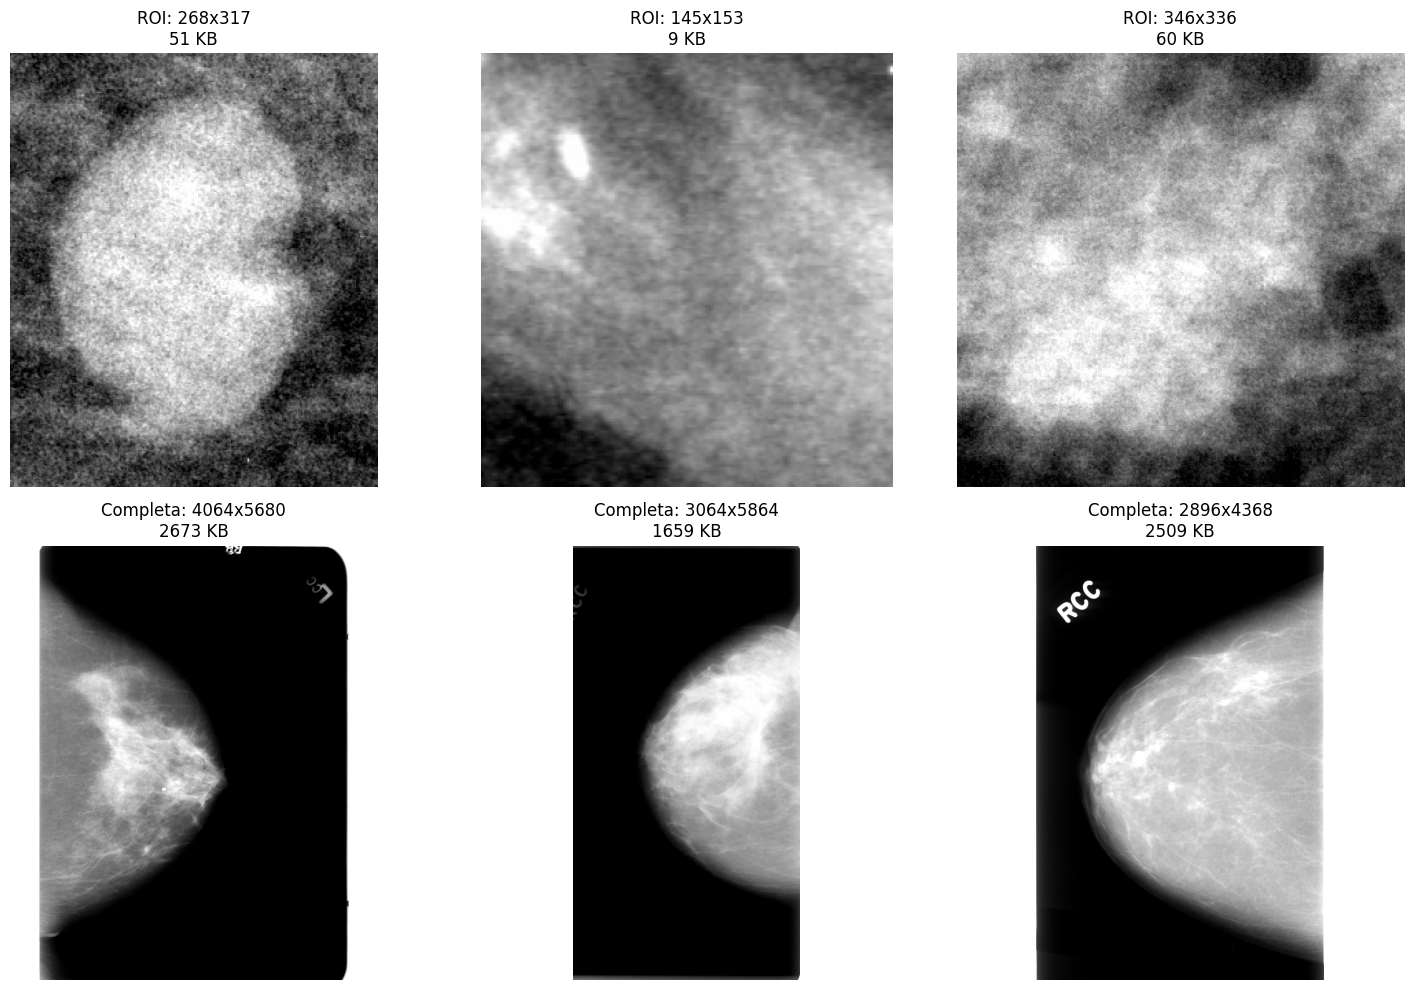


  VERIFICACAO DE PROBLEMAS
  Imagens completamente uniformes: 0
  Imagens com contraste muito baixo: 0
  Nenhum problema detectado na amostra.


In [36]:
import matplotlib.pyplot as plt
import random

jpgs = list(OUTPUT_ROOT.rglob("*.jpg"))
jpgs_pequenos = [f for f in jpgs if f.stat().st_size < 100*1024]
jpgs_grandes = [f for f in jpgs if f.stat().st_size > 1000*1024]

amostras_peq = random.sample(jpgs_pequenos, min(3, len(jpgs_pequenos)))
amostras_gra = random.sample(jpgs_grandes, min(3, len(jpgs_grandes)))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

print("VERIFICAÇÃO DE QUALIDADE\n")

for i, f in enumerate(amostras_peq):
    img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        axes[0, i].imshow(img, cmap='gray')
        axes[0, i].set_title(f"ROI: {img.shape[1]}x{img.shape[0]}\n{f.stat().st_size/1024:.0f} KB")
        axes[0, i].axis('off')
        
        print(f"ROI: {f.name}")
        print(f"  Dimensão: {img.shape[1]}x{img.shape[0]}")
        print(f"  Tamanho: {f.stat().st_size/1024:.0f} KB")
        print(f"  Range: [{img.min()}, {img.max()}]")
        print(f"  Média: {img.mean():.1f}, Std: {img.std():.1f}")
        print(f"  Valores únicos: {len(np.unique(img))}")

for i, f in enumerate(amostras_gra):
    img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        axes[1, i].imshow(img, cmap='gray')
        axes[1, i].set_title(f"Completa: {img.shape[1]}x{img.shape[0]}\n{f.stat().st_size/1024:.0f} KB")
        axes[1, i].axis('off')
        
        print(f"\nCompleta: {f.name}")
        print(f"  Dimensão: {img.shape[1]}x{img.shape[0]}")
        print(f"  Tamanho: {f.stat().st_size/1024:.0f} KB")
        print(f"  Range: [{img.min()}, {img.max()}]")
        print(f"  Média: {img.mean():.1f}, Std: {img.std():.1f}")
        print(f"  Valores únicos: {len(np.unique(img))}")

plt.tight_layout()
plt.show()

print(f"\nVERIFICAÇÃO DE PROBLEMAS")
pretas, brancas, baixo_contraste = 0, 0, 0

for f in jpgs[:500]:
    img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    if img.max() == img.min(): pretas += 1
    elif img.std() < 10: baixo_contraste += 1

print(f"  Imagens completamente uniformes: {pretas}")
print(f"  Imagens com contraste muito baixo: {baixo_contraste}")
if pretas == 0 and baixo_contraste == 0:
    print("  Nenhum problema detectado na amostra.")

### Nota de execução.
Este notebook foi refatorado para melhor legibilidade e padronização dos códigos após a sua execução original. A lógica do algoritmo foi preservada, e as saídas exibidas correspondem à execução do código original.